--- 1. HỒI QUY ĐƠN GIẢN ---
Hệ số chặn (Intercept): 494.84
Hệ số góc (Slope): 34.44
MSE: 34114.92
R^2 score: 0.9744


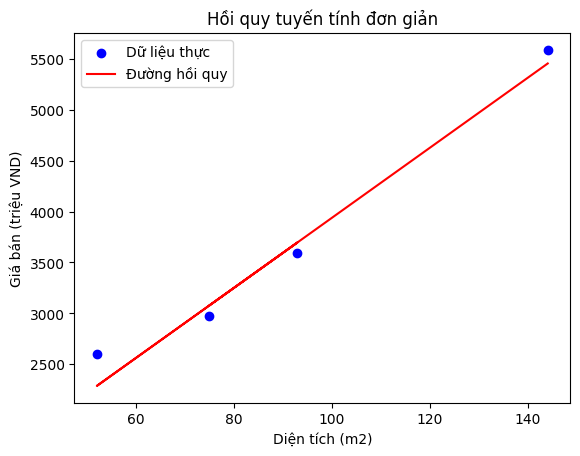


--- 2. THÊM DỮ LIỆU & ĐỘ NHIỄU CAO ---
MSE: 635623.49
R^2 score: 0.6682

--- 3. HỒI QUY ĐA BIẾN ---
Hệ số chặn (Intercept): 598.40
Hệ số hồi quy (Diện tích, Số phòng, Khoảng cách): [ 34.97314199 203.97376875 -49.62249698]
MSE: 34064.17
R^2 score: 0.9735


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tạo dữ liệu giả định (20 mẫu): Diện tích (m2) và Giá bán (triệu VND)
np.random.seed(42)
dien_tich = np.random.uniform(30, 150, (20, 1))

gia_ban = 500 + 35 * dien_tich + np.random.normal(0, 150, (20, 1))

X_train, X_test, y_train, y_test = train_test_split(dien_tich, gia_ban, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("--- 1. HỒI QUY ĐƠN GIẢN ---")
print(f"Hệ số chặn (Intercept): {model.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope): {model.coef_[0][0]:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2 score: {r2_score(y_test, y_pred):.4f}")

plt.scatter(X_test, y_test, color='blue', label='Dữ liệu thực')
plt.plot(X_test, y_pred, color='red', label='Đường hồi quy')
plt.xlabel('Diện tích (m2)')
plt.ylabel('Giá bán (triệu VND)')
plt.title('Hồi quy tuyến tính đơn giản')
plt.legend()
plt.show()

# 2. Tăng số lượng mẫu (500 mẫu) và tăng độ nhiễu (std = 800)
dien_tich_nhieu = np.random.uniform(30, 150, (500, 1))
gia_ban_nhieu = 500 + 35 * dien_tich_nhieu + np.random.normal(0, 800, (500, 1))

X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(dien_tich_nhieu, gia_ban_nhieu, test_size=0.2, random_state=42)

model_n = LinearRegression()
model_n.fit(X_train_n, y_train_n)
y_pred_n = model_n.predict(X_test_n)

print("\n--- 2. THÊM DỮ LIỆU & ĐỘ NHIỄU CAO ---")
print(f"MSE: {mean_squared_error(y_test_n, y_pred_n):.2f}")
print(f"R^2 score: {r2_score(y_test_n, y_pred_n):.4f}")

# 3. Thêm biến đầu vào: Diện tích (m2), Số phòng ngủ, Khoảng cách tới trung tâm (km)
n_samples = 500
dt = np.random.uniform(30, 150, n_samples)
so_phong = np.random.randint(1, 6, n_samples)
khoang_cach = np.random.uniform(1, 20, n_samples)

X_multi = np.column_stack((dt, so_phong, khoang_cach))

y_multi = 600 + 35 * dt + 200 * so_phong - 50 * khoang_cach + np.random.normal(0, 200, n_samples)

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_tr_m, y_tr_m)
y_pred_m = model_multi.predict(X_te_m)

print("\n--- 3. HỒI QUY ĐA BIẾN ---")
print(f"Hệ số chặn (Intercept): {model_multi.intercept_:.2f}")
print(f"Hệ số hồi quy (Diện tích, Số phòng, Khoảng cách): {model_multi.coef_}")
print(f"MSE: {mean_squared_error(y_te_m, y_pred_m):.2f}")
print(f"R^2 score: {r2_score(y_te_m, y_pred_m):.4f}")

Ví dụ 5 mẫu kiểm tra đầu tiên:
BMI: 37.5 | Xác suất mắc bệnh: 99.38% | Dự đoán: 1 | Thực tế: 1
BMI: 32.4 | Xác suất mắc bệnh: 92.85% | Dự đoán: 1 | Thực tế: 1
BMI: 18.6 | Xác suất mắc bệnh: 1.29% | Dự đoán: 0 | Thực tế: 0
BMI: 32.7 | Xác suất mắc bệnh: 93.71% | Dự đoán: 1 | Thực tế: 1
BMI: 27.3 | Xác suất mắc bệnh: 50.17% | Dự đoán: 1 | Thực tế: 0

Độ chính xác (Accuracy): 0.8833
Ma trận nhầm lẫn (Confusion Matrix):
[[25  5]
 [ 2 28]]


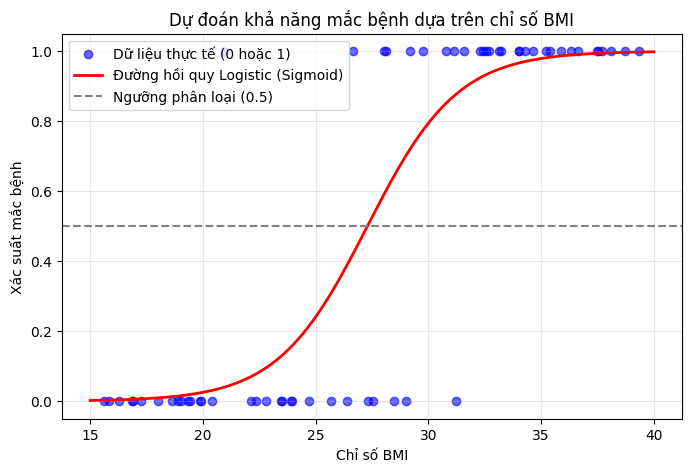

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Tạo dữ liệu mẫu giả lập (BMI từ 15 đến 40)
np.random.seed(42)
n_samples = 300
bmi = np.random.uniform(15, 40, (n_samples, 1))

xac_suat_thuc = 1 / (1 + np.exp(-0.5 * (bmi - 27)))
mac_benh = (np.random.rand(n_samples, 1) < xac_suat_thuc).astype(int).ravel()

X_train, X_test, y_train, y_test = train_test_split(bmi, mac_benh, test_size=0.2, random_state=42)

# 2 và 3. Xây dựng và huấn luyện mô hình Logistic Regression
model_log = LogisticRegression()
model_log.fit(X_train, y_train)

# 4. Dự đoán nhãn và xác suất trên tập kiểm tra
y_pred = model_log.predict(X_test)
y_prob = model_log.predict_proba(X_test)[:, 1] # Xác suất thuộc lớp 1 (Mắc bệnh)

print("Ví dụ 5 mẫu kiểm tra đầu tiên:")
for i in range(5):
    print(f"BMI: {X_test[i][0]:.1f} | Xác suất mắc bệnh: {y_prob[i]:.2%} | Dự đoán: {y_pred[i]} | Thực tế: {y_test[i]}")

# 5. Đánh giá hiệu quả mô hình
print(f"\nĐộ chính xác (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))

# 6. Trực quan hóa dữ liệu và đường hồi quy Logistic
bmi_range = np.linspace(15, 40, 300).reshape(-1, 1)
prob_curve = model_log.predict_proba(bmi_range)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Dữ liệu thực tế (0 hoặc 1)')
plt.plot(bmi_range, prob_curve, color='red', linewidth=2, label='Đường hồi quy Logistic (Sigmoid)')
plt.axhline(0.5, color='gray', linestyle='--', label='Ngưỡng phân loại (0.5)')
plt.xlabel('Chỉ số BMI')
plt.ylabel('Xác suất mắc bệnh')
plt.title('Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Kích thước dữ liệu:", df.shape)
print("Kiểm tra giá trị thiếu (Missing values):\n", df.isnull().sum())

X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R^2 score: {r2:.4f}")

Kích thước dữ liệu: (20640, 9)
Kiểm tra giá trị thiếu (Missing values):
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
MSE: 0.5559
RMSE: 0.7456
R^2 score: 0.5758
